In [22]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

import lpdo_utils
import noise_channels
from tqdm import tqdm
import quimb.tensor as qtn

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac} \usepackage{amsfonts} \usepackage{physics}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

def load_mo_results(filename, process_keys = ['observable', 'observable_mitigated', 'error']):
    """
    """
    with open(filename, 'r') as file:
        data_dict = json.load(file)

    for k in process_keys:
        data_dict[k] = np.real_if_close(np.array(data_dict[k], dtype = complex))
    return data_dict

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
mo_results_dict = {'opt_filename': 'mo-clifford_nq10_d30_bd200_gen_dict_bigger_231127_kyiv_50q_inv_opt_mpo_seed1_2023-12-08.json',
                   'true_filename': 'mo-clifford_nq10_d30_bd200_gen_dict_bigger_231127_kyiv_50q_inv_true_mpo_seed1_2023-12-08.json'}

mo_results = {k: load_mo_results(v) for k, v in mo_results_dict.items()}

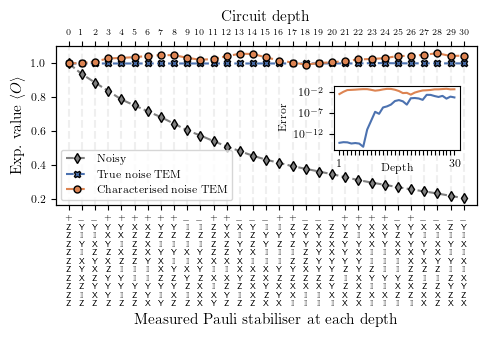

In [21]:
#######################
# CREATE XTICKS LABELS
#######################

# Separate signs from Pauli strings
signs = [p[0] for p in mo_results['opt_filename']['pauli_string']]
pauli_strings_no_sign = [p[1:] for p in mo_results['opt_filename']['pauli_string']]

# Create LateX versions of the xticks
xticks_labels = [''.join([r'$\textsf{' + ps + r'}$' + ' \n ' for ps in p])[:-3] for p in pauli_strings_no_sign]
xticks_labels2 = [p.replace('\\textsf{_}', '\\mathbb{I}') for p in xticks_labels]

# Fix the minus sign to be at the same height of the plus sign
signs = [r'\raisebox{0.0em}{$-$}' if s == '-' else '$+$' for s in signs]

# Join again signs and Pauli strings together
xticks_labels2 = [s + ' \n ' + p for s, p in zip(signs, xticks_labels2)]

##################
# CREATE PLOT
##################

# Plot with specified settings
fig, ax = plt.subplots(figsize=(5, 3.5))

# Noisy results (no TEM)
plt.plot(mo_results['opt_filename']['observable'].real, c = "grey", ls = "--", marker = 'd', **marker_options, label = "Noisy")

# Mitigation using the exact inverse of the noise
plt.plot(mo_results['true_filename']['observable_mitigated'].real, c = cmap[0], ls = "--", marker='X', **marker_options, label = "True noise TEM")

# Mitigation using the characterised noise
plt.plot(mo_results['opt_filename']['observable_mitigated'].real, c = cmap[1], ls = "--", marker='o', **marker_options, label = "Characterised noise TEM")

depths = range(len(mo_results['opt_filename']['observable']))
ax.set_xlim(min(depths)-1, max(depths)+1)

ax.set_xticks(depths, labels=xticks_labels2, fontsize = 6)
ax.set_xlabel("Measured Pauli stabiliser at each depth")

ax.legend(loc='lower left', fontsize=8)
ax.set_ylabel(r"Exp.~value $\expval{O}$")

ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(depths, labels = depths, fontsize = 6)
ax2.set_xlabel("Circuit depth", labelpad = 6)

# Subplot showing the error
err_ax = ax.inset_axes([0.66, 0.35, 0.3, 0.4])
err_ax.plot(range(1, len(mo_results['opt_filename']['observable'])), np.abs(mo_results['opt_filename']['error'])[1:], c = cmap[1], ls = "-")
err_ax.plot(range(1, len(mo_results['true_filename']['observable'])), np.abs(mo_results['true_filename']['error'])[1:], c = cmap[0], ls = "-")

err_ax.set_xticks(range(1, len(mo_results['true_filename']['observable'])))
err_ax.set_xticklabels([1] + ['']*(len(mo_results['true_filename']['observable']) - 3) + [len(mo_results['true_filename']['observable'])-1])
err_ax.set_yscale('log')
err_ax.set_ylabel("Error", fontsize = 8)
err_ax.set_xlabel("Depth", labelpad=-4, fontsize = 8)
err_ax.set_yticks([1e-12, 1e-7, 1e-2])

ax.grid(ls = "--", axis='x', lw = 1.5, alpha = 0.2)
plt.tight_layout()

plt.savefig(mo_results_dict['opt_filename'][:-5] + '.pdf', format="pdf")

In [16]:
import stim

n = 10
p = stim.PauliString('+' + 'Z'*n)
print(p)

for q, op in enumerate(['H_YZ', 'SQRT_Y_DAG', 'H_YZ', 'H', 'SQRT_X_DAG', 'Y', 'SQRT_X_DAG', 'H_YZ', 'H_XY', 'Y']):
    p = p.after(stim.CircuitInstruction(op, [q]))

for q, op in enumerate(['CNOT',]*5):
    p = p.after(stim.CircuitInstruction(op, [2*q, 2*q + 1]))

for q, op in enumerate(['X', 'SQRT_X_DAG', 'C_ZYX', 'SQRT_X', 'C_XYZ', 'SQRT_Y', 'C_XYZ', 'C_ZYX', 'H_XY', 'Z']):
    p = p.after(stim.CircuitInstruction(op, [q]))

for q, op in enumerate(['CNOT',]*4):
    p = p.after(stim.CircuitInstruction(op, [2*q + 1, 2*q + 2]))
    
print(p)

+ZZZZZZZZZZ
-Y_XZYXZYXZ


# Analyze Middle-Out performances

In [ ]:
#######################
# LOADING MPOs
#######################
#training_results_file = 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed1001.json'
training_results_file = 'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed12.json'

res = load_training_results(file_name=training_results_file)

# Find parameters attaining lowest test error
best_idx = np.where(res['test_loss'] == np.sort(res['test_loss'])[0])[0][0]
print(best_idx,)
opt_params = res['params'][-1]
num_qubits = len(opt_params)

# Create LPDO and MPO (in PTM form) with such optimal parametes
opt_lpdo = build_lpdo(tn_data = opt_params.values())   
#opt_lpdo, _ = training_functions.optimize_trace_preservation(opt_lpdo, steps=1000, plot_results=False)
opt_mpo = lpdo_to_mpo(opt_lpdo)

# Create true LPDO and MPO (in PTM form) for the corresponding noise
noise_type = res['noise_type']
true_lpdo = noise_channels.select_noise_channel(noise_type, num_qubits, tensor_type = 'lpdo')
true_mpo  = noise_channels.select_noise_channel(noise_type, num_qubits, tensor_type = 'mpo')

inv_opt_mpo  = mpo_utils.mpo_from_params_file(training_results_file, load_key = 'params_inv_opt_mpo')
inv_true_mpo = mpo_utils.mpo_from_params_file(training_results_file, load_key = 'params_inv_true_mpo')

print(lpdo_utils.trace_lpdo(opt_lpdo))
print(f"‖ LPDO_opt - LPDO_true ‖_Frob = {(opt_lpdo.distance(true_lpdo) / 2**num_qubits) ** 2}") 
print(f"‖ MPO_opt  - MPO_true ‖_Frob = {(opt_mpo.distance(true_mpo) / 2**num_qubits) ** 2}") 
print(f"‖ MPO_opt^-1  * MPO_opt  - Id ‖_Frob = {(inv_opt_mpo.apply(opt_mpo)).distance(qtn.MPO_identity_like(inv_opt_mpo))}") 
print(f"‖ MPO_true^-1 * MPO_true - Id ‖_Frob = {(true_mpo.apply(inv_true_mpo)).distance(qtn.MPO_identity_like(inv_true_mpo))}") 

In [ ]:
def pauli_index_to_string(pauli_index):
    index_to_key = {0: 'I', 1: 'X', 2: 'Y', 3: 'Z'}
    return [index_to_key[p] for p in pauli_index]

def pauli_string_to_index(pauli_string):
    # Remove unnecessary sign
    if (pauli_string[0] == '+') or (pauli_string[0] == '-'):
        pauli_string = pauli_string[1:]
    index_to_key = {'I': 0, '_': 0, 'X': 1, 'Y': 2, 'Z': 3}
    return [index_to_key[p] for p in pauli_string]

def pauli_index_to_multindex(pauli_index, state_space = 4):
    one_hot_matrix = np.zeros((len(pauli_index), state_space))
    one_hot_matrix[range(len(pauli_index)), pauli_index] = 1
    return one_hot_matrix

#pauli_strings = res_opt['pauli_string']
#pauli_strings = [p.replace('_', 'I') for p in pauli_strings]
#pauli_strings = [''.join(s) for s in np.random.choice(['I','I','I','I','I','I','X', 'Y', 'Z'], (30, num_qubits))]

pauli_strings = np.array([['I',]*num_qubits,]*50)

size = len(pauli_strings) // num_qubits
groups = [range(i*size, (i+1) * size) for i in range(len(pauli_strings) // size)]
pauli_weights = np.linspace(1, num_qubits, len(groups), dtype=int)

for pauli_weight, gidx in zip(pauli_weights, groups):
    for j in gidx:
        idx = np.random.choice(range(num_qubits), pauli_weight, replace=False)
        pauli_strings[j][idx] = np.random.choice(['X', 'Y', 'Z'], pauli_weight)   

pauli_strings = ['I'*num_qubits] + pauli_strings.tolist()
pauli_strings = [''.join(s) for s in pauli_strings]

In [ ]:
res_coeffs = {}

for p in tqdm(pauli_strings):

    pauli_index = pauli_string_to_index(p)
    pauli_index = pauli_index_to_multindex(pauli_index)
    
    in_mps = qtn.MPS_product_state(pauli_index, site_ind_id = 'k{}')
    out_mps = qtn.MPS_product_state(pauli_index, site_ind_id = 'b{}')
    
    res_coeffs [p] = {'opt_mpo' : (in_mps | opt_mpo | out_mps).contract(),
                      'true_mpo': (in_mps | true_mpo | out_mps).contract(),
                      'inv_opt_mpo': (in_mps | inv_opt_mpo | out_mps).contract(),
                      'inv_true_mpo': (in_mps | inv_true_mpo | out_mps).contract()
                      }
    
opt_mpo_val  = np.array([res_coeffs[p]['opt_mpo'] for p in pauli_strings])
true_mpo_val = np.array([res_coeffs[p]['true_mpo'] for p in pauli_strings])

inv_opt_mpo_val  = np.array([res_coeffs[p]['inv_opt_mpo'] for p in pauli_strings])
inv_true_mpo_val = np.array([res_coeffs[p]['inv_true_mpo'] for p in pauli_strings])

In [ ]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize = (12, 4), sharex=True)

xx = range(len(opt_mpo_val))
xticks_labels = [p + f': {m}' for m, p in enumerate(pauli_strings)]
ax1.plot(xx, opt_mpo_val, lw = 0, **marker_options, label = r"Characterised noise $\Lambda_{\boldsymbol{\theta}}$")
ax1.plot(xx, true_mpo_val, lw = 0, **marker_options, label = r"True noise $\Lambda$")
ax1.set_xticks(xx, labels = xticks_labels, rotation = 90, fontsize=8)
ax1.legend()

ax2.plot(xx, inv_opt_mpo_val, lw = 0, **marker_options, label = r"Inverse of characterised noise $\Lambda_{\boldsymbol{\theta}}^{-1}$")
ax2.plot(xx, inv_true_mpo_val, lw = 0, **marker_options, label = r"Inverse of true noise $\Lambda^{-1}$")
ax2.set_xticks(xx, labels = xticks_labels, rotation = 90, fontsize=8)
ax2.set_xticklabels(xticks_labels)
ax2.legend()

min_y = min(min(opt_mpo_val), min(true_mpo_val))
[ax1.text(0.5 + int(min(g) + (max(g) - min(g)) / 2),  min_y, f"{w+1}", ha="center") for w, g in enumerate(groups)]
ax1.vlines(0.5, min_y, 1, ls = "--", color="grey")
ax1.vlines([max(g) + 1.5 for g in groups], min_y, 1, ls = "--", color="grey")

min_y = min(min(inv_opt_mpo_val), min(inv_true_mpo_val))
max_y = max(max(inv_opt_mpo_val), max(inv_true_mpo_val))
ax2.vlines(0.5, min_y, max_y, ls = "--", color="grey")
ax2.vlines([max(g) + 1.5 for g in groups], min_y, max_y, ls = "--", color="grey")

plt.tight_layout()
#plt.savefig('Locality_error_analysis_' + training_results_file + '.pdf', format="pdf")

In [ ]:
true_mpo_val

In [ ]:
inv_true_mpo_val 

In [ ]:
def accumulate_results(val_list):
    return np.array([*accumulate(val_list, lambda a, b: a*b)])

true_noise_stepwise_mitigation = true_mpo_val * inv_true_mpo_val
true_noise_ideal_mitigation = accumulate_results(true_noise_stepwise_mitigation[1:])

opt_noise_stepwise_mitigation = true_mpo_val * inv_opt_mpo_val
opt_noise_stepwise_mitigation[0] = 1 # Step 0 is not mitigted
opt_noise_ideal_mitigation = accumulate_results(opt_noise_stepwise_mitigation)

fig = plt.figure(figsize = (6, 4))
plt.plot(opt_noise_ideal_mitigation, **marker_options, label = "Characterised noise: $\prod_{i=1}^{\\textrm{Depth}} [\Lambda]_{{ii}} \cdot [\Lambda^{-1}]_{{ii}}$")
plt.plot(true_noise_ideal_mitigation, **marker_options, label = "True noise: $\prod_{i=1}^{\\textrm{Depth}} [\Lambda]_{{ii}} \cdot [\Lambda^{-1}]_{{ii}}$")

noisy_evolution = accumulate_results(true_mpo_val)
plt.plot(noisy_evolution, label = "Noisy Observable")

plt.xticks(xx, labels = xticks_labels, rotation = 90, fontsize=8)

plt.legend()
plt.tight_layout()
#plt.savefig("infinite_bd_" + training_results_file + '.pdf', format = 'pdf')

In [ ]:
plt.plot(res_opt2['observable_mitigated'], **marker_options, label = "Middle-out (bond dim. = 200), characterised noise")
plt.plot(opt_noise_ideal_mitigation, **marker_options, c='c', label = "Middle-out (no compression), characterised noise")
plt.legend()
#plt.savefig("infinite_bd_" + opt_filename + '.pdf', format = 'pdf')

In [ ]:
opt_noise_stepwise_mitigation

In [ ]:
opt_noise_stepwise_mitigation

In [ ]:
opt_noise_ideal_mitigation

In [ ]:
def accumulate_results(val_list):
    return np.array([*accumulate(val_list, lambda a, b: a - b)])

In [ ]:
ll = [1,4,5,4,5,6]

np.abs([ll[k] - ll[k+1] for k in range(len(ll)-1)]).mean()

In [ ]:
for i in range(5):
    print(i)
    if i == 2:
        break

In [ ]:
try:
    for i in range(int(1e12)):
        print(i)
except KeyboardInterrupt:
    print("Exited")

print("anna")

In [ ]:
i

In [ ]:
########################################################################
lowest_losses = np.sort(res['test_loss'])[:1]
best_idx = [np.where(res['test_loss'] == ll)[0][0] for ll in lowest_losses]
opt_params2 = [res['params'][idx] for idx in best_idx]

final_params = {k : [] for k in opt_params2[0].keys()}
    
for p in opt_params2:
    for k, v in p.items():
        final_params[k].append(v)

for k in final_params.keys():
    final_params[k] = np.real_if_close(np.mean(np.array(final_params[k]), axis=0))

####################################################################################